In [1]:
import json
import random

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import torch
from sentence_transformers import SentenceTransformer
from sklearn.manifold import TSNE

/home/infres/tandriam-25/fil_rouge/venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
print(f"Version PyTorch : {torch.__version__}")
print(f"Version CUDA intégrée à PyTorch : {torch.version.cuda}")
print(f"Type d'architecture : {torch.backends.cudnn.version()}")

Version PyTorch : 2.6.0+cu124
Version CUDA intégrée à PyTorch : 12.4
Type d'architecture : 90100


In [3]:
import sys

import torch

print(f"Version de Python : {sys.version.split()[0]}")
print(f"Version de PyTorch : {torch.__version__}")

# Vérification principale
if torch.cuda.is_available():
    device = torch.device("cuda")
    count = torch.cuda.device_count()
    name = torch.cuda.get_device_name(0)

    print("\n✅ SUPER ! Un GPU est disponible.")
    print(f"   --> Nombre de GPU(s) : {count}")
    print(f"   --> Modèle du GPU 0  : {name}")
    print(f"   --> Mémoire actuelle allouée : {round(torch.cuda.memory_allocated(0)/1024**3, 1)} GB")

else:
    device = torch.device("cpu")
    print("\n❌ AÏE... Aucun GPU détecté.")
    print("   --> Le code tournera sur le CPU (ce sera beaucoup plus lent).")
    print("   --> Vérifie ton installation CUDA ou tes drivers.")

print(f"\nAppareil sélectionné pour les calculs : {device}")

Version de Python : 3.13.11
Version de PyTorch : 2.6.0+cu124

✅ SUPER ! Un GPU est disponible.
   --> Nombre de GPU(s) : 1
   --> Modèle du GPU 0  : Tesla P100-PCIE-16GB
   --> Mémoire actuelle allouée : 0.0 GB

Appareil sélectionné pour les calculs : cuda


In [4]:
# Configuration
sns.set_theme(style="whitegrid")

def visualize_graph_embedding(file_path, n_samples=2000, top_n_cat=5):
    # --- CHECK GPU ---
    device = "cpu"
    if torch.cuda.is_available():
        device = "cuda"
    elif torch.backends.mps.is_available():
        device = "mps"

    print(f"📂 Analyse du fichier : {file_path}...")

    # --- ETAPE 1 : ESTIMATION DU NOMBRE DE LIGNES ---
    total_lines = 0
    with open(file_path, 'r', encoding='utf-8') as f:
        for _ in f: total_lines += 1

    # --- ETAPE 2 : RESERVOIR SAMPLING ---
    target_load = n_samples * 2
    probability = min(1.0, (target_load * 1.5) / total_lines)

    data = []
    with open(file_path, 'r', encoding='utf-8') as f:
        for line in f:
            if random.random() > probability: continue
            try:
                obj = json.loads(line.strip())
                data.append(obj)
            except: pass

    df = pd.DataFrame(data)
    if len(df) == 0: return

    # --- ETAPE 3 : FILTRAGE "TOP N" ---
    top_categories = df['typelabel'].value_counts().nlargest(top_n_cat).index.tolist()
    df_filtered = df[df['typelabel'].isin(top_categories)].copy()

    if len(df_filtered) > n_samples:
        df_filtered = df_filtered.sample(n=n_samples, random_state=42)

    print(f"✅ Données filtrées : {len(df_filtered)} produits.")

    # Chargement du modèle une seule fois
    model = SentenceTransformer('all-MiniLM-L6-v2', device=device)

    # --- ETAPE 4 : DOUBLE GÉNÉRATION (Titre vs Titre + Desc) ---
    col_titre = 'designation' if 'designation' in df_filtered.columns else 'titre'
    col_desc = 'description' if 'description' in df_filtered.columns else None

    # Nettoyage de base
    df_filtered[col_titre] = df_filtered[col_titre].fillna("")
    if col_desc:
        df_filtered[col_desc] = df_filtered[col_desc].fillna("")

    # Configurations à tester
    configs = [
        {"name": "Title", "input": df_filtered[col_titre]},
        {"name": "Title + Description",
         "input": df_filtered[col_titre] + " " + df_filtered[col_desc].apply(lambda x: " ".join(str(x).split()[:]))}
    ]

    for config in configs:
        print(f"\n🚀 Génération du graphe : {config['name']}...")

        # Vectorisation
        embeddings = model.encode(config['input'].tolist(), show_progress_bar=True, batch_size=64, device=device)

        # Projection t-SNE
        perp = min(30, len(df_filtered) - 1)
        tsne = TSNE(n_components=2, random_state=42, perplexity=perp, n_jobs=-1)
        embeddings_2d = tsne.fit_transform(embeddings)

        df_filtered['x'] = embeddings_2d[:, 0]
        df_filtered['y'] = embeddings_2d[:, 1]

        # Affichage
        plt.figure(figsize=(14, 8))
        sns.scatterplot(
            data=df_filtered,
            x='x', y='y',
            hue='typelabel',
            palette='bright',
            style='typelabel',
            s=70,
            alpha=0.7,
            edgecolor='k'
        )
        plt.title(f"Embedding Space : {config['name']} (Top {top_n_cat} categories)", fontsize=15)
        plt.legend(bbox_to_anchor=(1.05, 1), loc=2, borderaxespad=0.)
        plt.tight_layout()
        plt.show()

📂 Analyse du fichier : dataset/train.jsonl...
✅ Données filtrées : 10000 produits.


Loading weights: 100%|██████████| 103/103 [00:00<00:00, 518.05it/s, Materializing param=pooler.dense.weight]                             
BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.



🚀 Génération du graphe : Title...


Batches: 100%|██████████| 157/157 [00:03<00:00, 45.34it/s]


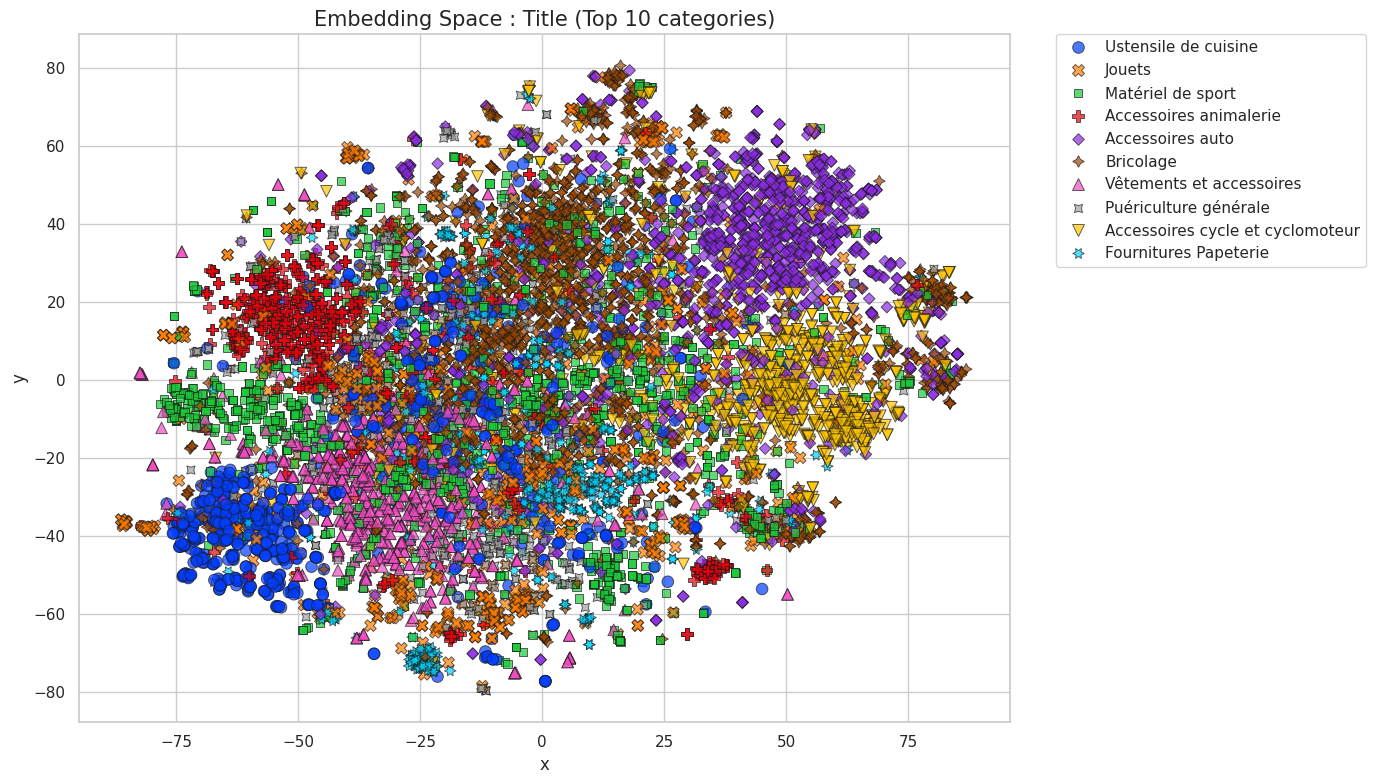


🚀 Génération du graphe : Title + Description...


Batches: 100%|██████████| 157/157 [00:12<00:00, 12.25it/s]


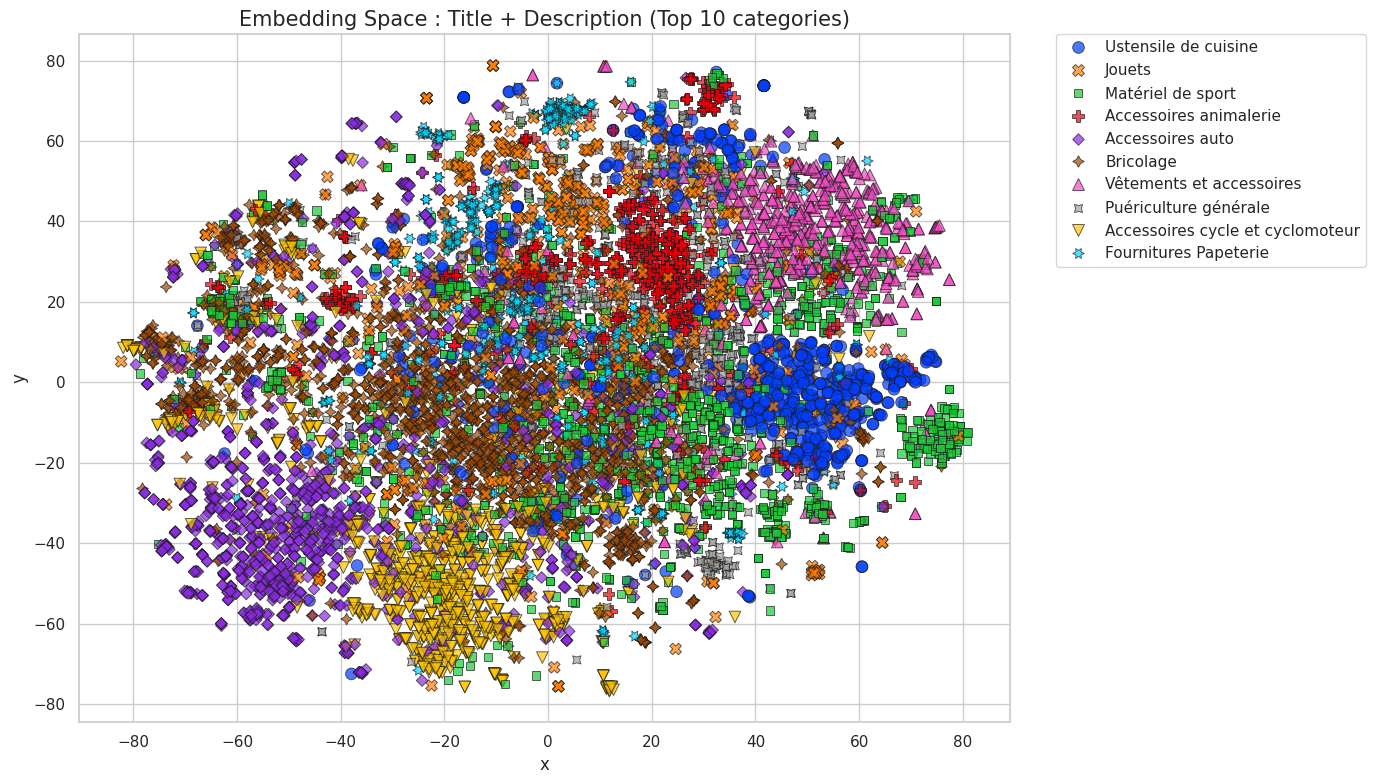

In [6]:
visualize_graph_embedding("dataset/train.jsonl", n_samples=10000, top_n_cat=10)